In [1]:
import pandas as pd
import numpy as np

In [2]:
# Load datasets
sales_data = pd.read_csv("C:/Users/telvi/Downloads/GRADENCE TASK/WEEK-2/sales_data.csv")

product_info = pd.read_csv("C:/Users/telvi/Downloads/GRADENCE TASK/WEEK-2/product_info.csv")

customer_info = pd.read_csv("C:/Users/telvi/Downloads/GRADENCE TASK/WEEK-2/customer_info.csv")

In [3]:
# Check structure
sales_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          2999 non-null   object 
 1   customer_id       2998 non-null   object 
 2   product_id        2995 non-null   object 
 3   quantity          2997 non-null   object 
 4   unit_price        2999 non-null   float64
 5   order_date        2998 non-null   object 
 6   delivery_status   2997 non-null   object 
 7   payment_method    2997 non-null   object 
 8   region            3000 non-null   object 
 9   discount_applied  2483 non-null   float64
dtypes: float64(2), object(8)
memory usage: 234.5+ KB


In [4]:
sales_data.head()

,order_id,customer_id,product_id,quantity,unit_price,order_date,delivery_status,payment_method,region,discount_applied
0,O966977,C00397,P0022,3,39.25,06-07-2025,Delivered,PayPal,Central,0.00
1,O696648,C00236,P0023,5,18.92,06-07-2025,DELAYED,credit card,North,0.00
2,O202644,C00492,P0011,1,29.68,07-07-2025,delivered,Bank Transfer,North,0.15
3,O501803,C00031,P0003,1,32.76,08-07-2025,Cancelled,Credit Card,Central,0.20
4,O322242,C00495,P0016,1,47.62,08-07-2025,DELAYED,Credit Card,West,0.20


In [5]:
sales_data.describe()

,unit_price,discount_applied
count,2999.000000,2483.000000
mean,28.945388,0.100262
std,12.085893,0.069987
min,8.000000,0.000000
25%,18.830000,0.050000
50%,28.630000,0.100000
75%,39.640000,0.150000
max,49.990000,0.200000


In [6]:
# 2. Clean the Data

In [7]:
# Check missing values
sales_data.isnull().sum()

order_id              1
customer_id           2
product_id            5
quantity              3
unit_price            1
order_date            2
delivery_status       3
payment_method        3
region                0
discount_applied    517
dtype: int64

In [8]:
# Check duplicates
sales_data.duplicated().sum()

np.int64(0)

In [9]:
# For this project, we should not blindly drop rows because that would remove a large amount of data

In [10]:
# Fill missing discounts with 0 Since a missing discount usually means no discount was applied:
sales_data['discount_applied'] = sales_data['discount_applied'].fillna(0)

In [11]:
# Fill categorical columns with "Unknown"
sales_data['customer_id'] = sales_data['customer_id'].fillna('Unknown')
sales_data['product_id'] = sales_data['product_id'].fillna('Unknown')
sales_data['delivery_status'] = sales_data['delivery_status'].fillna('Unknown')
sales_data['payment_method'] = sales_data['payment_method'].fillna('Unknown')

In [12]:
# ### Converting the Quantity Column to Numeric

#The `quantity` column was initially stored as an object (string) data type rather than a numeric data type. This prevented numerical operations such as calculating summary statistics, averages, and medians.
# To resolve this issue, the column has to be converted to a numeric format using

sales_data['quantity'] = pd.to_numeric(
    sales_data['quantity'],
    errors='coerce'
)

In [13]:
sales_data['quantity'].dtype

dtype('float64')

In [14]:
# # Fill numeric columns with the medisn
sales_data['quantity'] = sales_data['quantity'].fillna(
    sales_data['quantity'].median()
)

sales_data['unit_price'] = sales_data['unit_price'].fillna(
    sales_data['unit_price'].median()
)

sales_data['discount_applied'] = sales_data['discount_applied'].fillna(0)

In [15]:
# verify
sales_data[['quantity','unit_price','discount_applied']].dtypes

quantity            float64
unit_price          float64
discount_applied    float64
dtype: object

In [16]:
#Handle Missing order_id
# Since order_id is a unique identifier, it cannot be reliably imputed.
# checking the row
sales_data[sales_data['order_id'].isnull()]

,order_id,customer_id,product_id,quantity,unit_price,order_date,delivery_status,payment_method,region,discount_applied
862,NaN,C00237,P0013,1.0,39.26,11-05-2025,Delayed,Credit Card,West,0.2


In [17]:
# Remove order_id
sales_data = sales_data.dropna(subset=['order_id'])

In [18]:
# Handle Missing order_date
#Check the rows:
sales_data[sales_data['order_date'].isnull()]

,order_id,customer_id,product_id,quantity,unit_price,order_date,delivery_status,payment_method,region,discount_applied
1373,O746155,C00158,P0003,2.0,45.43,NaN,Delivered,credit card,Central,0.00
2090,O218231,C00324,P0014,4.0,12.76,NaN,Delayed,credit card,East,0.15


In [19]:
# For this project, filling with the most common date is acceptable:
sales_data['order_date'] = sales_data['order_date'].fillna(
    sales_data['order_date'].mode()[0]
)

In [20]:
# Verify 
sales_data.isnull().sum()

order_id            0
customer_id         0
product_id          0
quantity            0
unit_price          0
order_date          0
delivery_status     0
payment_method      0
region              0
discount_applied    0
dtype: int64

In [21]:
# Standardise Text Formatting

In [22]:
#vCheck unique values in each text column
print("Delivery Status:")
print(sales_data['delivery_status'].unique())

print("\nPayment Method:")
print(sales_data['payment_method'].unique())

print("\nRegion:")
print(sales_data['region'].unique())

Delivery Status:
['Delivered' ' DELAYED' 'delivered' ' Cancelled ' 'Delayed' 'delrd'
 'delyd' 'Unknown']

Payment Method:
['PayPal' 'credit card' 'Bank Transfer' 'Credit Card' 'Unknown'
 'bank transfr']

Region:
['Central' 'North' 'West' 'East' 'South' 'nrth']


In [23]:
# Check value counts. This helps confirm there are no duplicate categories caused by inconsistent formatting:
print(sales_data['delivery_status'].value_counts())

print(sales_data['payment_method'].value_counts())

print(sales_data['region'].value_counts())

delivery_status
Delivered      637
delivered      594
 DELAYED       591
 Cancelled     591
Delayed        581
Unknown          3
delrd            1
delyd            1
Name: count, dtype: int64
payment_method
Bank Transfer    780
PayPal           763
Credit Card      734
credit card      718
Unknown            3
bank transfr       1
Name: count, dtype: int64
region
North      605
Central    603
East       602
South      596
West       592
nrth         1
Name: count, dtype: int64


In [24]:
# Check for leading/trailing spaces
sales_data['delivery_status'].str.startswith(' ').sum()

np.int64(1182)

In [25]:
# data quality
sales_data[['delivery_status', 'payment_method', 'region']].head(10)

,delivery_status,payment_method,region
0,Delivered,PayPal,Central
1,DELAYED,credit card,North
2,delivered,Bank Transfer,North
3,Cancelled,Credit Card,Central
4,DELAYED,Credit Card,West
5,Delayed,Bank Transfer,North
6,delivered,PayPal,Central
7,Delivered,Credit Card,East
8,delivered,PayPal,Central
9,DELAYED,Credit Card,South


In [26]:
# Standardise delivery_status

sales_data['delivery_status'] = (
    sales_data['delivery_status']
    .str.strip()
    .str.title()
)

# Standardise payment_method
sales_data['payment_method'] = (
    sales_data['payment_method']
    .str.strip()
    .str.title()
)

# Standardise region
sales_data['region'] = (
    sales_data['region']
    .str.strip()
    .str.title()
)

In [27]:
# Fix Typographical Errors
sales_data['delivery_status'] = sales_data['delivery_status'].replace(
    'Delrd',
    'Delivered'
)

In [28]:
#verify result
print(sales_data['delivery_status'].unique())

print(sales_data['payment_method'].unique())

print(sales_data['region'].unique())

['Delivered' 'Delayed' 'Cancelled' 'Delyd' 'Unknown']
['Paypal' 'Credit Card' 'Bank Transfer' 'Unknown' 'Bank Transfr']
['Central' 'North' 'West' 'East' 'South' 'Nrth']


In [29]:
# Fix the typos
sales_data['delivery_status'] = sales_data['delivery_status'].replace({
    'Delyd': 'Delayed'
})

sales_data['payment_method'] = sales_data['payment_method'].replace({
    'Bank Transfr': 'Bank Transfer'
})

sales_data['region'] = sales_data['region'].replace({
    'Nrth': 'North'
})

In [30]:
# verify again
print("Delivery Status:")
print(sales_data['delivery_status'].unique())

print("\nPayment Method:")
print(sales_data['payment_method'].unique())

print("\nRegion:")
print(sales_data['region'].unique())

Delivery Status:
['Delivered' 'Delayed' 'Cancelled' 'Unknown']

Payment Method:
['Paypal' 'Credit Card' 'Bank Transfer' 'Unknown']

Region:
['Central' 'North' 'West' 'East' 'South']


In [31]:
# Convert Date Column
# check for data type
print(sales_data['order_date'].dtype)

object


In [32]:
sales_data['order_date'] = pd.to_datetime(
    sales_data['order_date'],
    dayfirst=True,
    errors='coerce'
)

In [33]:
# check the data type again
print(sales_data['order_date'].dtype)

datetime64[ns]


In [34]:
sales_data[['order_date']].head()

,order_date
0,2025-07-06
1,2025-07-06
2,2025-07-07
3,2025-07-08
4,2025-07-08


In [35]:
# check for failed conversion
sales_data['order_date'].isnull().sum()

np.int64(0)

In [36]:
# Ensure quan ty, unit_price, and discount_applied are all non-negave  (Validate Numeric Columns)
# Check for negative values:
sales_data[
    (sales_data['quantity'] < 0) |
    (sales_data['unit_price'] < 0) |
    (sales_data['discount_applied'] < 0)
]

,order_id,customer_id,product_id,quantity,unit_price,order_date,delivery_status,payment_method,region,discount_applied


In [37]:
#  Final Validation
sales_data.shape

(2999, 10)

In [38]:
sales_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2999 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          2999 non-null   object        
 1   customer_id       2999 non-null   object        
 2   product_id        2999 non-null   object        
 3   quantity          2999 non-null   float64       
 4   unit_price        2999 non-null   float64       
 5   order_date        2999 non-null   datetime64[ns]
 6   delivery_status   2999 non-null   object        
 7   payment_method    2999 non-null   object        
 8   region            2999 non-null   object        
 9   discount_applied  2999 non-null   float64       
dtypes: datetime64[ns](1), float64(3), object(6)
memory usage: 257.7+ KB


In [39]:
sales_data.head()

,order_id,customer_id,product_id,quantity,unit_price,order_date,delivery_status,payment_method,region,discount_applied
0,O966977,C00397,P0022,3.0,39.25,2025-07-06,Delivered,Paypal,Central,0.00
1,O696648,C00236,P0023,5.0,18.92,2025-07-06,Delayed,Credit Card,North,0.00
2,O202644,C00492,P0011,1.0,29.68,2025-07-07,Delivered,Bank Transfer,North,0.15
3,O501803,C00031,P0003,1.0,32.76,2025-07-08,Cancelled,Credit Card,Central,0.20
4,O322242,C00495,P0016,1.0,47.62,2025-07-08,Delayed,Credit Card,West,0.20


In [40]:
# Check structure of another dataset "product_info
product_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   product_id     30 non-null     object 
 1   product_name   30 non-null     object 
 2   category       30 non-null     object 
 3   launch_date    30 non-null     object 
 4   base_price     30 non-null     float64
 5   supplier_code  30 non-null     object 
dtypes: float64(1), object(5)
memory usage: 1.5+ KB


In [41]:
 product_info.head()

,product_id,product_name,category,launch_date,base_price,supplier_code
0,P0001,Storage Product 39,Storage,11-03-25,15.88,S339
1,P0002,Cleaning Product 82,Cleaning,18-08-24,34.23,S974
2,P0003,Cleaning Product 85,Cleaning,15-07-24,7.92,S745
3,P0004,Kitchen Product 82,Kitchen,19-04-25,9.13,S589
4,P0005,Personal Care Product 1,Personal Care,20-10-24,31.10,S559


In [42]:
 product_info.describe

<bound method NDFrame.describe of    product_id              product_name       category launch_date  \
0       P0001        Storage Product 39        Storage    11-03-25   
1       P0002       Cleaning Product 82       Cleaning    18-08-24   
2       P0003       Cleaning Product 85       Cleaning    15-07-24   
3       P0004        Kitchen Product 82        Kitchen    19-04-25   
4       P0005   Personal Care Product 1  Personal Care    20-10-24   
5       P0006       Cleaning Product 16       Cleaning    09-10-24   
6       P0007  Personal Care Product 64  Personal Care    30-09-24   
7       P0008        Storage Product 47        Storage    29-08-24   
8       P0009       Outdoors Product 13       Outdoors    18-04-25   
9       P0010       Cleaning Product 70       Cleaning    14-08-24   
10      P0011        Kitchen Product 53        Kitchen    25-03-25   
11      P0012       Cleaning Product 29       Cleaning    19-04-25   
12      P0013       Cleaning Product 94       Cleaning  

# 2. Clean the Data

In [43]:
# Check missing values
product_info.isnull().sum()

product_id       0
product_name     0
category         0
launch_date      0
base_price       0
supplier_code    0
dtype: int64

In [44]:
# Check duplicates
product_info.duplicated().sum()

np.int64(0)

In [45]:
# launch_date is the wrong data type

In [46]:
product_info['launch_date'] = pd.to_datetime(
    product_info['launch_date'],
    dayfirst=True,
    errors='coerce'
)

C:\Users\telvi\AppData\Local\Temp\ipykernel_1688\3737322098.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  product_info['launch_date'] = pd.to_datetime(


In [47]:
#verify
product_info['launch_date'].isna().sum()

np.int64(0)

In [48]:
product_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   product_id     30 non-null     object        
 1   product_name   30 non-null     object        
 2   category       30 non-null     object        
 3   launch_date    30 non-null     datetime64[ns]
 4   base_price     30 non-null     float64       
 5   supplier_code  30 non-null     object        
dtypes: datetime64[ns](1), float64(1), object(4)
memory usage: 1.5+ KB


In [49]:
product_info.head()

,product_id,product_name,category,launch_date,base_price,supplier_code
0,P0001,Storage Product 39,Storage,2025-03-11,15.88,S339
1,P0002,Cleaning Product 82,Cleaning,2024-08-18,34.23,S974
2,P0003,Cleaning Product 85,Cleaning,2024-07-15,7.92,S745
3,P0004,Kitchen Product 82,Kitchen,2025-04-19,9.13,S589
4,P0005,Personal Care Product 1,Personal Care,2024-10-20,31.10,S559


In [50]:
# checking for space
for col in product_info.select_dtypes(include='object').columns:
    count = (
        product_info[col] != product_info[col].str.strip()
    ).sum()

    print(f"{col}: {count} rows with leading/trailing spaces")

product_id: 0 rows with leading/trailing spaces
product_name: 0 rows with leading/trailing spaces
category: 0 rows with leading/trailing spaces
supplier_code: 0 rows with leading/trailing spaces


In [51]:
# Cleaning the data for product_info
# exploring the data
customer_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   customer_id   497 non-null    object
 1   email         494 non-null    object
 2   signup_date   496 non-null    object
 3   gender        496 non-null    object
 4   region        497 non-null    object
 5   loyalty_tier  498 non-null    object
dtypes: object(6)
memory usage: 23.6+ KB


In [52]:
customer_info.isnull().sum()

customer_id     3
email           6
signup_date     4
gender          4
region          3
loyalty_tier    2
dtype: int64

In [53]:
# check for duplicate records
customer_info.duplicated().sum()

np.int64(0)

In [54]:
# investigate missing roll
customer_info[customer_info.isnull().any(axis=1)]

,customer_id,email,signup_date,gender,region,loyalty_tier
16,C00017,nathanielmartin@sellers.com,NaN,Male,West,GOLD
87,C00088,NaN,06-01-25,male,West,bronze
89,C00090,kevinperkins@yahoo.com,05-02-25,femle,East,NaN
94,C00095,jeremy24@erickson.com,23-07-24,male,NaN,GOLD
147,C00148,NaN,02-03-25,Male,West,GOLD
162,C00163,ronald45@mcdaniel.com,10-08-24,Female,NaN,Silver
225,C00226,victorhughes@wilson.com,NaN,Male,East,gold
251,C00252,phillipjensen@yahoo.com,21-02-25,NaN,North,bronze
253,NaN,mark16@parker.com,22-02-25,femle,South,bronze
298,C00299,harttammy@hotmail.com,27-01-25,NaN,Central,Silver


In [55]:
# Drop rows with missing customer_id
# Since customer_id is the key used to merge with sales data, these records cannot be reliably linked to purchases.

customer_info = customer_info.dropna(subset=['customer_id'])

In [56]:
# Fill missing emails, Missing emails don't affect the merge.
customer_info['email'] = customer_info['email'].fillna('unknown@example.com')

In [57]:
# Fill missing gender
customer_info['gender'] = customer_info['gender'].fillna('Unknown')

In [58]:
# Fill missing region 
customer_info['region'] = customer_info['region'].fillna('Unknown')

In [59]:
# Fill missing loyalty tier
customer_info['loyalty_tier'] = customer_info['loyalty_tier'].fillna('Unknown')

In [60]:
# Missing signup dates, we have 4 rows with missing signup dates
# For this project, I would keep them and leave them as missing after converting to datetime.

customer_info['signup_date'] = pd.to_datetime(
    customer_info['signup_date'],
    dayfirst=True,
    errors='coerce'
)

C:\Users\telvi\AppData\Local\Temp\ipykernel_1688\1516281661.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  customer_info['signup_date'] = pd.to_datetime(


In [61]:
customer_info['signup_date'].isna().sum()

np.int64(4)

In [62]:
# tandardise Gender
customer_info['gender'] = (
    customer_info['gender']
    .str.strip()
    .str.lower()
    .replace({
        'male': 'Male',
        'female': 'Female',
        'femle': 'Female',
        'other': 'Other'
    })
)

In [63]:
# Standardise Loyalty Tier
customer_info['loyalty_tier'] = (
    customer_info['loyalty_tier']
    .str.strip()
    .str.lower()
    .replace({
        'gold': 'Gold',
        'gld': 'Gold',
        'silver': 'Silver',
        'bronze': 'Bronze',
        'brnze': 'Bronze'
    })
)

In [64]:
# Standardise Region
customer_info['region'] = customer_info['region'].str.strip().str.title()

In [65]:
# verify cleaning
customer_info.isnull().sum()

customer_id     0
email           0
signup_date     4
gender          0
region          0
loyalty_tier    0
dtype: int64

In [66]:
# Fix the missing "gender values"
customer_info['gender'] = customer_info['gender'].fillna('Unknown')

In [67]:
# Run for final check before merging
customer_info.duplicated().sum()

np.int64(0)

In [68]:
customer_info['gender'].value_counts(dropna=False)

gender
Female     249
Male       168
Other       76
unknown      4
Name: count, dtype: int64

In [69]:
customer_info['loyalty_tier'].value_counts(dropna=False)

loyalty_tier
Gold       265
Silver     116
Bronze     113
unknown      2
sllver       1
Name: count, dtype: int64

In [70]:
# You still have:unknown (lowercase) and sllver (misspelling of Silver)
customer_info['loyalty_tier'] = (
    customer_info['loyalty_tier']
    .replace({
        'sllver': 'Silver',
        'unknown': 'Unknown'
    })
)

In [71]:
# verify
customer_info['loyalty_tier'].value_counts(dropna=False)

loyalty_tier
Gold       265
Silver     117
Bronze     113
Unknown      2
Name: count, dtype: int64

In [72]:
# final validate check
customer_info.isnull().sum()

customer_id     0
email           0
signup_date     4
gender          0
region          0
loyalty_tier    0
dtype: int64

In [73]:
customer_info.duplicated().sum()

np.int64(0)

In [74]:
customer_info['gender'].unique()

array(['Male', 'Female', 'Other', 'unknown'], dtype=object)

In [75]:
customer_info['loyalty_tier'].unique()

array(['Silver', 'Gold', 'Bronze', 'Unknown'], dtype=object)

# 3. Merge the Data  

In [76]:
# Merge sales_data with product_info using product_id  
merged_df = sales_data.merge(
    product_info,
    on='product_id',
    how='left'
)

In [77]:
#verify the merge
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2999 entries, 0 to 2998
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          2999 non-null   object        
 1   customer_id       2999 non-null   object        
 2   product_id        2999 non-null   object        
 3   quantity          2999 non-null   float64       
 4   unit_price        2999 non-null   float64       
 5   order_date        2999 non-null   datetime64[ns]
 6   delivery_status   2999 non-null   object        
 7   payment_method    2999 non-null   object        
 8   region            2999 non-null   object        
 9   discount_applied  2999 non-null   float64       
 10  product_name      2994 non-null   object        
 11  category          2994 non-null   object        
 12  launch_date       2994 non-null   datetime64[ns]
 13  base_price        2994 non-null   float64       
 14  supplier_code     2994 n

In [78]:
# Then merge the result with customer_info using customer_id 
merged_df = (
    sales_data
    .merge(product_info, on='product_id', how='left')
    .merge(customer_info, on='customer_id', how='left')
)

In [79]:
# verify the final merge
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2999 entries, 0 to 2998
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          2999 non-null   object        
 1   customer_id       2999 non-null   object        
 2   product_id        2999 non-null   object        
 3   quantity          2999 non-null   float64       
 4   unit_price        2999 non-null   float64       
 5   order_date        2999 non-null   datetime64[ns]
 6   delivery_status   2999 non-null   object        
 7   payment_method    2999 non-null   object        
 8   region_x          2999 non-null   object        
 9   discount_applied  2999 non-null   float64       
 10  product_name      2994 non-null   object        
 11  category          2994 non-null   object        
 12  launch_date       2994 non-null   datetime64[ns]
 13  base_price        2994 non-null   float64       
 14  supplier_code     2994 n

In [80]:
merged_df.head()

,order_id,customer_id,product_id,quantity,unit_price,order_date,delivery_status,payment_method,region_x,discount_applied,product_name,category,launch_date,base_price,supplier_code,email,signup_date,gender,region_y,loyalty_tier
0,O966977,C00397,P0022,3.0,39.25,2025-07-06,Delivered,Paypal,Central,0.00,Cleaning Product 86,Cleaning,2024-10-04,19.77,S924,jacquelinemartin@mills-logan.com,2024-09-08,Female,North,Silver
1,O696648,C00236,P0023,5.0,18.92,2025-07-06,Delayed,Credit Card,North,0.00,Outdoors Product 32,Outdoors,2025-01-18,36.04,S907,georgeweber@morgan.com,2024-08-06,Other,North,Gold
2,O202644,C00492,P0011,1.0,29.68,2025-07-07,Delivered,Bank Transfer,North,0.15,Kitchen Product 53,Kitchen,2025-03-25,11.08,S645,lcook@walters-smith.com,2024-09-25,Male,Central,Gold
3,O501803,C00031,P0003,1.0,32.76,2025-07-08,Cancelled,Credit Card,Central,0.20,Cleaning Product 85,Cleaning,2024-07-15,7.92,S745,smoore@gmail.com,2024-07-28,Female,Central,Gold
4,O322242,C00495,P0016,1.0,47.62,2025-07-08,Delayed,Credit Card,West,0.20,Cleaning Product 53,Cleaning,2025-02-20,26.71,S715,mcclainkatherine@hotmail.com,2024-09-18,Male,Central,Gold


In [81]:
merged_df.shape

(2999, 20)

In [82]:
# Use how='le ' to preserve all sales transac ons  
# first merge
merged_df = sales_data.merge(
    product_info,
    on='product_id',
    how='left'
)

In [83]:
# second merge
merged_df = merged_df.merge(
    customer_info,
    on='customer_id',
    how='left'
)
print(merged_df.shape)

(2999, 20)


In [84]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2999 entries, 0 to 2998
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          2999 non-null   object        
 1   customer_id       2999 non-null   object        
 2   product_id        2999 non-null   object        
 3   quantity          2999 non-null   float64       
 4   unit_price        2999 non-null   float64       
 5   order_date        2999 non-null   datetime64[ns]
 6   delivery_status   2999 non-null   object        
 7   payment_method    2999 non-null   object        
 8   region_x          2999 non-null   object        
 9   discount_applied  2999 non-null   float64       
 10  product_name      2994 non-null   object        
 11  category          2994 non-null   object        
 12  launch_date       2994 non-null   datetime64[ns]
 13  base_price        2994 non-null   float64       
 14  supplier_code     2994 n

In [85]:
# Save the merged dataset as merged_df  
merged_df.to_csv('merged_df.csv', index=False)

In [86]:
# Inspect merged_df using .info() and .head() to confirm merge success  
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2999 entries, 0 to 2998
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          2999 non-null   object        
 1   customer_id       2999 non-null   object        
 2   product_id        2999 non-null   object        
 3   quantity          2999 non-null   float64       
 4   unit_price        2999 non-null   float64       
 5   order_date        2999 non-null   datetime64[ns]
 6   delivery_status   2999 non-null   object        
 7   payment_method    2999 non-null   object        
 8   region_x          2999 non-null   object        
 9   discount_applied  2999 non-null   float64       
 10  product_name      2994 non-null   object        
 11  category          2994 non-null   object        
 12  launch_date       2994 non-null   datetime64[ns]
 13  base_price        2994 non-null   float64       
 14  supplier_code     2994 n

In [87]:
merged_df.head()

,order_id,customer_id,product_id,quantity,unit_price,order_date,delivery_status,payment_method,region_x,discount_applied,product_name,category,launch_date,base_price,supplier_code,email,signup_date,gender,region_y,loyalty_tier
0,O966977,C00397,P0022,3.0,39.25,2025-07-06,Delivered,Paypal,Central,0.00,Cleaning Product 86,Cleaning,2024-10-04,19.77,S924,jacquelinemartin@mills-logan.com,2024-09-08,Female,North,Silver
1,O696648,C00236,P0023,5.0,18.92,2025-07-06,Delayed,Credit Card,North,0.00,Outdoors Product 32,Outdoors,2025-01-18,36.04,S907,georgeweber@morgan.com,2024-08-06,Other,North,Gold
2,O202644,C00492,P0011,1.0,29.68,2025-07-07,Delivered,Bank Transfer,North,0.15,Kitchen Product 53,Kitchen,2025-03-25,11.08,S645,lcook@walters-smith.com,2024-09-25,Male,Central,Gold
3,O501803,C00031,P0003,1.0,32.76,2025-07-08,Cancelled,Credit Card,Central,0.20,Cleaning Product 85,Cleaning,2024-07-15,7.92,S745,smoore@gmail.com,2024-07-28,Female,Central,Gold
4,O322242,C00495,P0016,1.0,47.62,2025-07-08,Delayed,Credit Card,West,0.20,Cleaning Product 53,Cleaning,2025-02-20,26.71,S715,mcclainkatherine@hotmail.com,2024-09-18,Male,Central,Gold


In [88]:
# 4. Feature Engineering 
# Create the following new columns:  
# revenue = quan ty × unit_price × (1 - discount_applied)  
# order_week = ISO week from order_date  
# price_band = Categorise unit price as Low (<£15), Medium (£15–30), High (>£30)  
# days_to_order = Days between launch_date and order_date  
# email_domain = Extract domain from email (e.g., gmail.com)  
# is_late = True if delivery_status is "Delayed"  
# Use func ons like .dt, .apply(), .map(), or pd.cut() where appropriate. 

In [89]:
# 1. Revenue
merged_df['revenue'] = (
    merged_df['quantity']
    * merged_df['unit_price']
    * (1 - merged_df['discount_applied'])
)

# 2. Order Week (ISO Week Number)
merged_df['order_week'] = (
    merged_df['order_date']
    .dt.isocalendar()
    .week
)

# 3. Price Band
merged_df['price_band'] = pd.cut(
    merged_df['unit_price'],
    bins=[0, 15, 30, float('inf')],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

# 4. Days Between Product Launch and Order
merged_df['days_to_order'] = (
    merged_df['order_date']
    - merged_df['launch_date']
).dt.days

# 5. Email Domain
merged_df['email_domain'] = (
    merged_df['email']
    .str.split('@')
    .str[-1]
)

# 6. Late Delivery Flag
merged_df['is_late'] = (
    merged_df['delivery_status']
    .str.strip()
    .str.title()
    == 'Delayed'
)

In [90]:
# there was erro due to we merged customer_info twice, which createderror, 
#You should only have one set of customer columns.

In [91]:
#check
print(merged_df.columns)

Index(['order_id', 'customer_id', 'product_id', 'quantity', 'unit_price',
       'order_date', 'delivery_status', 'payment_method', 'region_x',
       'discount_applied', 'product_name', 'category', 'launch_date',
       'base_price', 'supplier_code', 'email', 'signup_date', 'gender',
       'region_y', 'loyalty_tier', 'revenue', 'order_week', 'price_band',
       'days_to_order', 'email_domain', 'is_late'],
      dtype='object')


In [92]:
merged_df[['email_x','email_y']].head()

KeyError: "None of [Index(['email_x', 'email_y'], dtype='object')] are in the [columns]"

In [ ]:
merged_df = (
    sales_data
    .merge(product_info, on='product_id', how='left')
    .merge(customer_info, on='customer_id', how='left')
)

In [ ]:
merged_df.columns

Index(['order_id', 'customer_id', 'product_id', 'quantity', 'unit_price',
       'order_date', 'delivery_status', 'payment_method', 'region_x',
       'discount_applied', 'product_name', 'category', 'launch_date',
       'base_price', 'supplier_code', 'email', 'signup_date', 'gender',
       'region_y', 'loyalty_tier'],
      dtype='object')

In [ ]:
# 1. Revenue
merged_df['revenue'] = (
    merged_df['quantity']
    * merged_df['unit_price']
    * (1 - merged_df['discount_applied'])
)

# 2. Order Week (ISO Week Number)
merged_df['order_week'] = (
    merged_df['order_date']
    .dt.isocalendar()
    .week
)

# 3. Price Band
merged_df['price_band'] = pd.cut(
    merged_df['unit_price'],
    bins=[0, 15, 30, float('inf')],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

# 4. Days Between Product Launch and Order
merged_df['days_to_order'] = (
    merged_df['order_date']
    - merged_df['launch_date']
).dt.days

# 5. Email Domain
merged_df['email_domain'] = (
    merged_df['email']
    .str.split('@')
    .str[-1]
)

# 6. Late Delivery Flag
merged_df['is_late'] = (
    merged_df['delivery_status']
    .str.strip()
    .str.title()
    == 'Delayed'
)

In [ ]:
# verify
merged_df[['quantity',
           'unit_price',
           'discount_applied',
           'revenue']].head()

,quantity,unit_price,discount_applied,revenue
0,3.0,39.25,0.00,117.750
1,5.0,18.92,0.00,94.600
2,1.0,29.68,0.15,25.228
3,1.0,32.76,0.20,26.208
4,1.0,47.62,0.20,38.096


In [ ]:
# checking summary statistics
merged_df['revenue'].describe()

count    2999.000000
mean       80.265432
std        53.559610
min         6.800000
25%        36.641500
50%        67.212500
75%       116.788500
max       249.350000
Name: revenue, dtype: float64

In [ ]:
# Verify All Feature Engineering Columns
merged_df[
    [
        'revenue',
        'order_week',
        'price_band',
        'days_to_order',
        'email_domain',
        'is_late'
    ]
].head()


,revenue,order_week,price_band,days_to_order,email_domain,is_late
0,117.750,27,High,275.0,mills-logan.com,False
1,94.600,27,Medium,169.0,morgan.com,True
2,25.228,28,Medium,104.0,walters-smith.com,False
3,26.208,28,High,358.0,gmail.com,False
4,38.096,28,High,138.0,hotmail.com,True


In [ ]:
# 5. Create Summary Tables  

In [ ]:
# Before Moving to Summary Tables
#Check:
merged_df[
    [
        'revenue',
        'order_week',
        'price_band',
        'days_to_order',
        'email_domain',
        'is_late'
    ]
].isnull().sum()

revenue           0
order_week        0
price_band        0
days_to_order     5
email_domain     26
is_late           0
dtype: int64

In [ ]:
# treat missing valuse
merged_df[
    merged_df['days_to_order'].isnull()
][['product_id','launch_date','order_date']]

,product_id,launch_date,order_date
569,Unknown,NaT,2025-05-22
613,Unknown,NaT,2025-05-24
1266,Unknown,NaT,2025-05-31
1840,Unknown,NaT,2025-06-19
2802,Unknown,NaT,2025-06-30


In [ ]:
# Leave as Missing

# Keep:
merged_df['days_to_order'].isnull().sum()

np.int64(5)

In [ ]:
merged_df['days_to_order'] = merged_df['days_to_order'].fillna(np.nan)

In [ ]:
# check the current email column name 
[col for col in merged_df.columns if 'email' in col.lower()]

['email', 'email_domain']

In [ ]:
merged_df[
    merged_df['email_domain'].isnull()
][['customer_id', 'email']]

,customer_id,email
80,C00372,NaN
186,C00254,NaN
350,C00372,NaN
392,C00471,NaN
505,C00471,NaN
595,C00471,NaN
601,C00471,NaN
742,C00471,NaN
851,Unknown,NaN
958,C00372,NaN


In [ ]:
merged_df['email_domain'] = (
    merged_df['email']
    .fillna('unknown@example.com')
    .str.split('@')
    .str[-1]
)

In [ ]:
# verify 
merged_df['email_domain'].isnull().sum()

np.int64(0)

In [ ]:
merged_df[
    merged_df['email_domain'].isnull()
][['customer_id','email']]

,customer_id,email


In [ ]:
# Weekly Revenue Trends by Region
weekly_revenue = (
    merged_df
    .groupby(['order_week', 'region_x'])['revenue']
    .sum()
    .reset_index()
)

weekly_revenue.head()

,order_week,region_x,revenue
0,14,Central,68.7600
1,14,East,70.1230
2,14,North,195.1840
3,14,West,53.8365
4,15,Central,16.0650


In [ ]:
# Product category performance (revenue, quan ty, discount)  
# (Revenue, Quantity, Discount)
category_performance = (
    merged_df
    .groupby('category')
    .agg(
        total_revenue=('revenue', 'sum'),
        total_quantity=('quantity', 'sum'),
        avg_discount=('discount_applied', 'mean')
    )
    .reset_index()
)

category_performance

,category,total_revenue,total_quantity,avg_discount
0,Cleaning,93825.8940,3592.0,0.085590
1,Kitchen,33993.0415,1229.0,0.075558
2,Outdoors,40201.2860,1525.0,0.082087
3,Personal Care,24916.6365,902.0,0.086755
4,Storage,47168.5175,1736.0,0.080763


In [ ]:
# sort by rebenue
category_performance.sort_values(
    by='total_revenue',
    ascending=False
)

,category,total_revenue,total_quantity,avg_discount
0,Cleaning,93825.8940,3592.0,0.085590
4,Storage,47168.5175,1736.0,0.080763
2,Outdoors,40201.2860,1525.0,0.082087
1,Kitchen,33993.0415,1229.0,0.075558
3,Personal Care,24916.6365,902.0,0.086755


In [ ]:
# Customer Behaviour by Loyalty Tier and Signup Month
# First create a signup month feature:
merged_df['signup_month'] = (
    merged_df['signup_date']
    .dt.to_period('M')
    .astype(str)
)

In [ ]:
customer_behaviour = (
    merged_df
    .groupby(['loyalty_tier', 'signup_month'])
    .agg(
        customers=('customer_id', 'nunique'),
        orders=('order_id', 'count'),
        revenue=('revenue', 'sum')
    )
    .reset_index()
)

customer_behaviour.head()

,loyalty_tier,signup_month,customers,orders,revenue
0,Bronze,2024-07,10,57,4038.7480
1,Bronze,2024-08,10,46,3831.0110
2,Bronze,2024-09,7,36,2685.4130
3,Bronze,2024-10,12,53,4247.2735
4,Bronze,2024-11,9,50,4149.2955


In [ ]:
# Delivery Performance by Region and Price Band
delivery_performance = (
    merged_df
    .groupby(['region_x', 'price_band'])
    .agg(
        total_orders=('order_id', 'count'),
        delayed_orders=('is_late', 'sum')
    )
    .reset_index()
)

delivery_performance['delay_rate'] = (
    delivery_performance['delayed_orders']
    / delivery_performance['total_orders']
    * 100
)

delivery_performance

C:\Users\telvi\AppData\Local\Temp\ipykernel_19988\1098233928.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['region_x', 'price_band'])


,region_x,price_band,total_orders,delayed_orders,delay_rate
0,Central,Low,113,43,38.053097
1,Central,Medium,225,88,39.111111
2,Central,High,265,104,39.245283
3,East,Low,96,40,41.666667
4,East,Medium,239,102,42.677824
5,East,High,267,109,40.823970
6,North,Low,107,41,38.317757
7,North,Medium,206,91,44.174757
8,North,High,293,106,36.177474
9,South,Low,98,33,33.673469


In [ ]:
# Preferred Payment Methods by Loyalty Tier
payment_preferences = (
    merged_df
    .groupby(['loyalty_tier', 'payment_method'])
    .size()
    .reset_index(name='order_count')
)

payment_preferences

,loyalty_tier,payment_method,order_count
0,Bronze,Bank Transfer,179
1,Bronze,Credit Card,283
2,Bronze,Paypal,163
3,Gold,Bank Transfer,406
4,Gold,Credit Card,841
5,Gold,Paypal,430
6,Gold,Unknown,2
7,Silver,Bank Transfer,191
8,Silver,Credit Card,306
9,Silver,Paypal,162


In [ ]:
# To find the most popular payment method per loyalty tier:
preferred_payment = (
    payment_preferences
    .sort_values(
        'order_count',
        ascending=False
    )
    .groupby('loyalty_tier')
    .head(1)
)

preferred_payment

,loyalty_tier,payment_method,order_count
4,Gold,Credit Card,841
8,Silver,Credit Card,306
1,Bronze,Credit Card,283
11,Unknown,Credit Card,6


In [ ]:
# quick validation
weekly_revenue.shape
category_performance.shape
customer_behaviour.shape
delivery_performance.shape
payment_preferences.shape

(13, 3)

# 6. Visual Explora on  

In [ ]:
# Line Plot – Weekly Revenue Trends by Region
# Prepare the data
weekly_revenue = (
    merged_df
    .groupby(['order_week', 'region_x'])['revenue']
    .sum()
    .reset_index()
)

weekly_revenue.head()

,order_week,region_x,revenue
0,14,Central,68.7600
1,14,East,70.1230
2,14,North,195.1840
3,14,West,53.8365
4,15,Central,16.0650


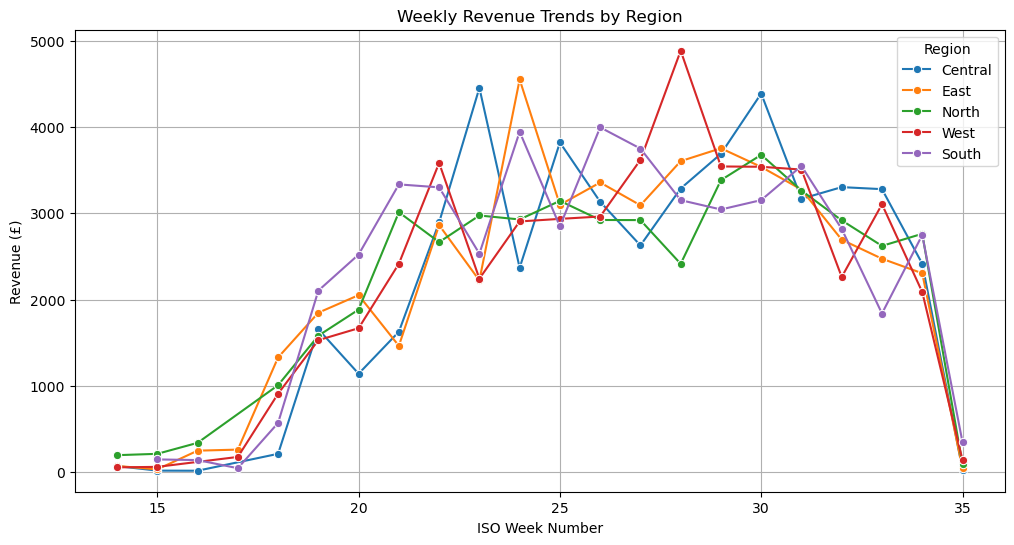

In [ ]:
# Create the visualization
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

sns.lineplot(
    data=weekly_revenue,
    x='order_week',
    y='revenue',
    hue='region_x',
    marker='o'
)

plt.title('Weekly Revenue Trends by Region')
plt.xlabel('ISO Week Number')
plt.ylabel('Revenue (£)')
plt.legend(title='Region')
plt.grid(True)

plt.show()

In [ ]:
# 2. Bar chart - top 5 categories by revenue  

In [ ]:
# For the Bar Chart – Top 5 Categories by Revenue, first create the summary table:
top_categories = (
    merged_df
    .groupby('category')['revenue']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .reset_index()
)

top_categories

,category,revenue
0,Cleaning,93825.8940
1,Storage,47168.5175
2,Outdoors,40201.2860
3,Kitchen,33993.0415
4,Personal Care,24916.6365


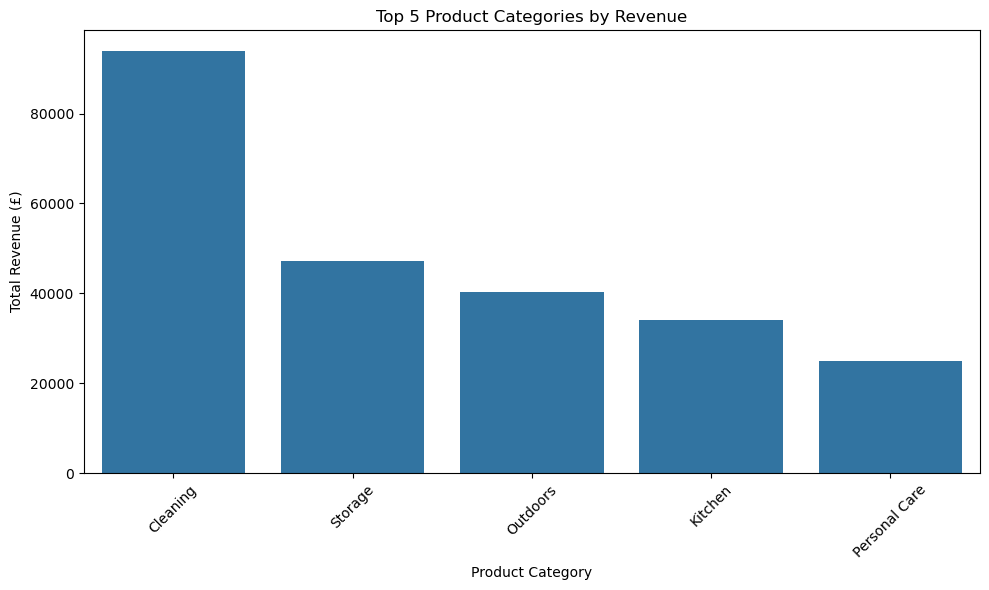

In [ ]:
# Plot the Chart
plt.figure(figsize=(10,6))

sns.barplot(
    data=top_categories,
    x='category',
    y='revenue'
)

plt.title('Top 5 Product Categories by Revenue')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue (£)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Boxplot - quan ty vs discount across categories  

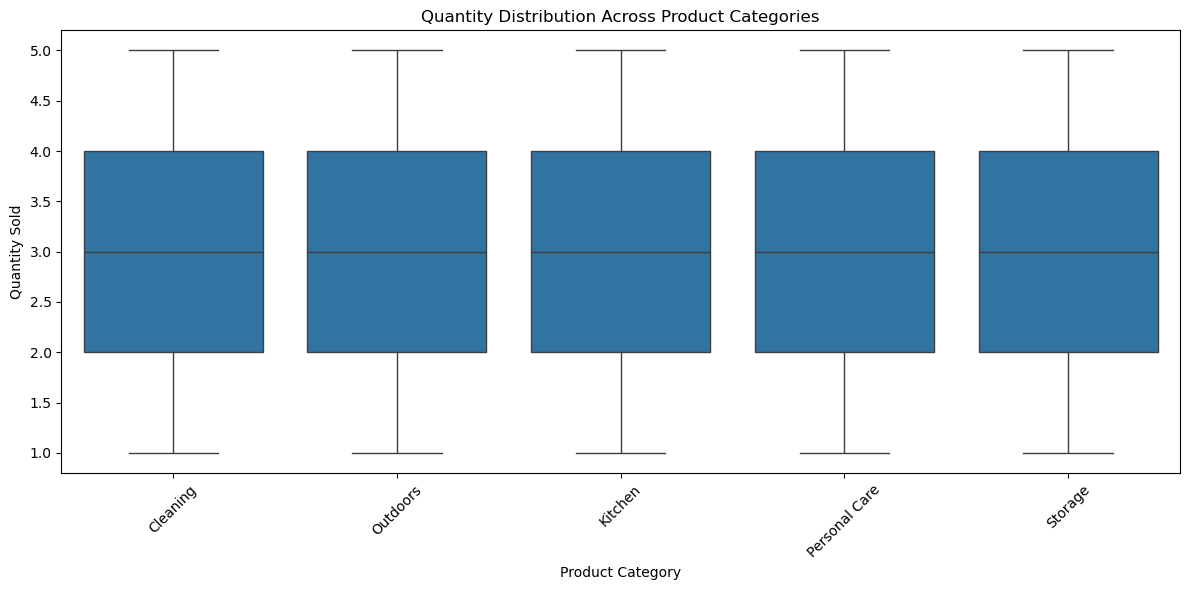

In [ ]:
# option 1 Quantity Distribution by Category (Most Common)
plt.figure(figsize=(12,6))

sns.boxplot(
    data=merged_df,
    x='category',
    y='quantity'
)

plt.title('Quantity Distribution Across Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Quantity Sold')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

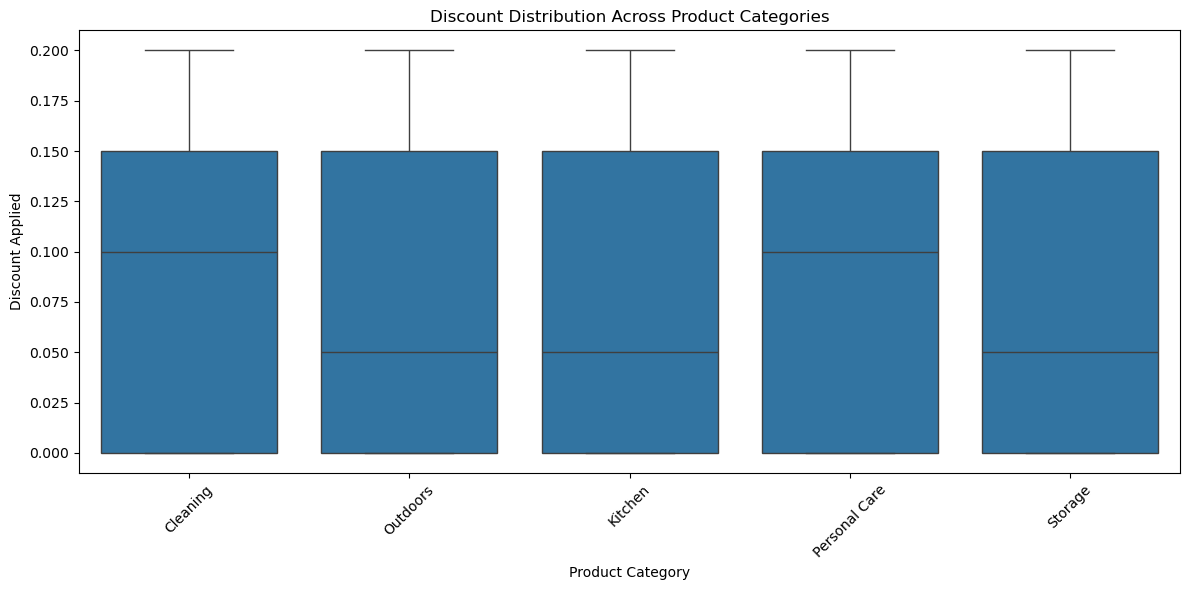

In [ ]:
# Option 2: Discount Distribution by Category
plt.figure(figsize=(12,6))

sns.boxplot(
    data=merged_df,
    x='category',
    y='discount_applied'
)

plt.title('Discount Distribution Across Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Discount Applied')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# 4. Heatmap - correla on between revenue, discount, and quan ty
# Create the Correlation Matrix
corr_matrix = merged_df[
    ['revenue', 'quantity', 'discount_applied']
].corr()

corr_matrix

,revenue,quantity,discount_applied
revenue,1.000000,0.721403,-0.118482
quantity,0.721403,1.000000,-0.008473
discount_applied,-0.118482,-0.008473,1.000000


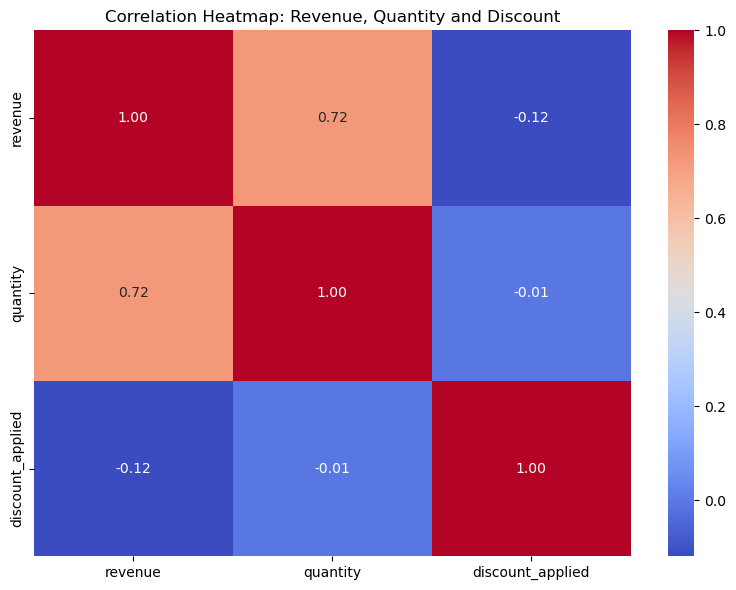

In [ ]:
# Plot the Heatmap
plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap: Revenue, Quantity and Discount')
plt.tight_layout()

plt.show()

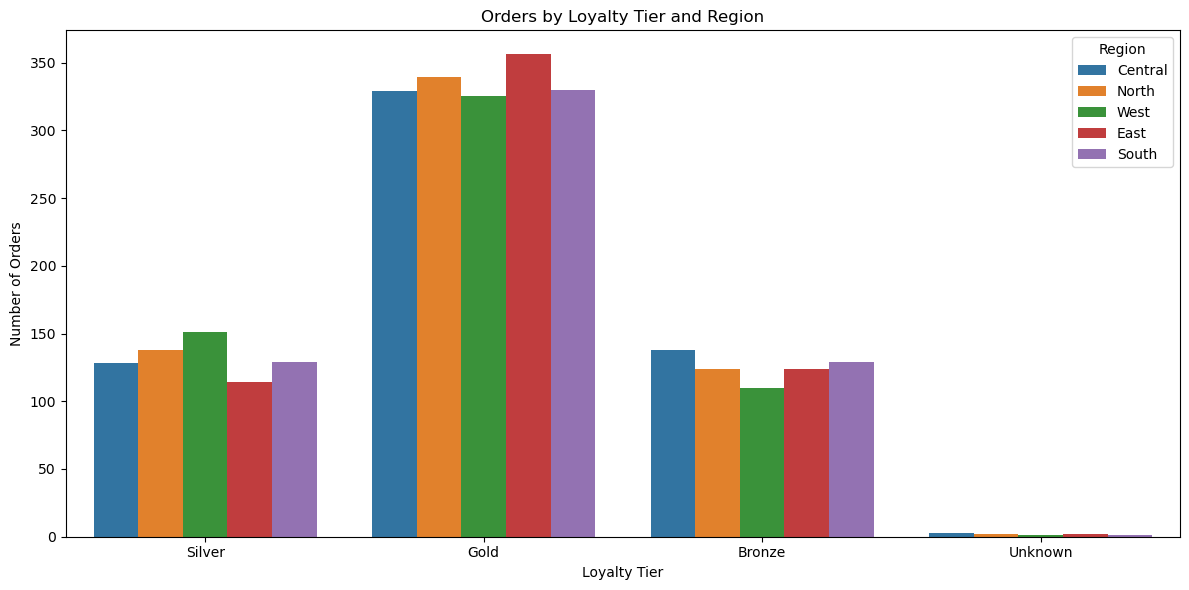

In [ ]:
# 5. Countplot – Orders by Loyalty Tier (with hue = Region), 
# Visualisation

plt.figure(figsize=(12,6))

sns.countplot(
    data=merged_df,
    x='loyalty_tier',
    hue='region_x'
)

plt.title('Orders by Loyalty Tier and Region')
plt.xlabel('Loyalty Tier')
plt.ylabel('Number of Orders')
plt.legend(title='Region')

plt.tight_layout()
plt.show()


In [ ]:
# 6. Stacked bar or pie - delivery status by price band  
# Create the Summary Table
delivery_status_priceband = pd.crosstab(
    merged_df['price_band'],
    merged_df['delivery_status']
)

delivery_status_priceband

delivery_status,Cancelled,Delayed,Delivered,Unknown
price_band,,,,
Low,108,187,195,1
Medium,220,441,457,0
High,263,545,580,2


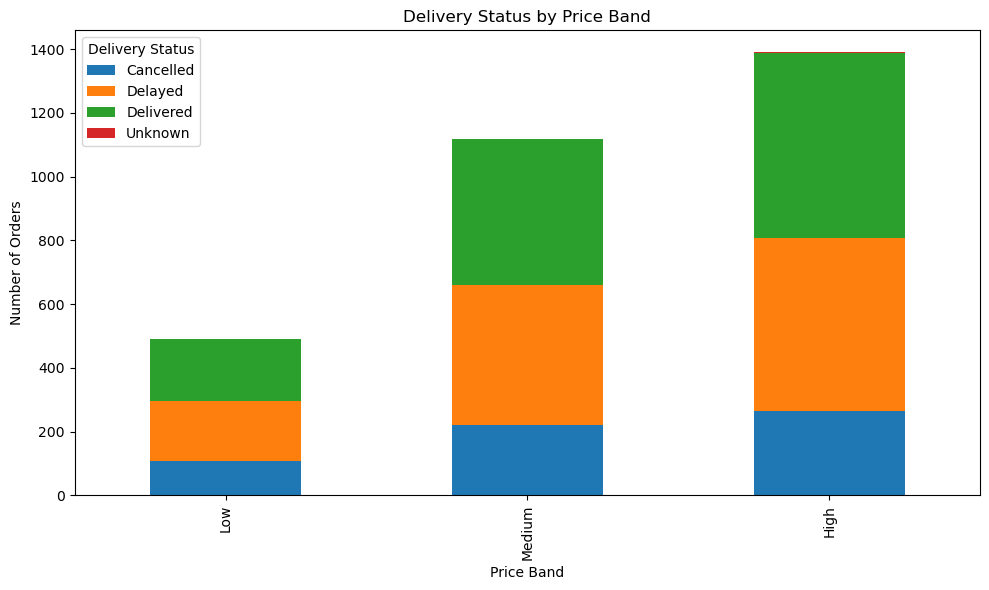

In [ ]:
# Create the Stacked Bar Chart
import matplotlib.pyplot as plt

delivery_status_priceband.plot(
    kind='bar',
    stacked=True,
    figsize=(10,6)
)

plt.title('Delivery Status by Price Band')
plt.xlabel('Price Band')
plt.ylabel('Number of Orders')
plt.legend(title='Delivery Status')

plt.tight_layout()
plt.show()

# 7. Business Ques ons to Answer (In PDF Report)  

In [ ]:
# 1. Which product categories drive the most revenue, and in which regions?  
# create the analysis table 
category_region_revenue = (
    merged_df
    .groupby(['category', 'region_x'])['revenue']
    .sum()
    .reset_index()
    .sort_values('revenue', ascending=False)
)

category_region_revenue.head(10)

,category,region_x,revenue
1,Cleaning,East,19975.3310
3,Cleaning,South,19058.8510
2,Cleaning,North,18766.1035
0,Cleaning,Central,18018.8375
4,Cleaning,West,18006.7710
24,Storage,West,10014.4465
21,Storage,East,9604.4205
20,Storage,Central,9489.2450
23,Storage,South,9345.3590
13,Outdoors,South,9327.4165


In [ ]:
# Find the top categories overall
top_categories = (
    merged_df
    .groupby('category')['revenue']
    .sum()
    .sort_values(ascending=False)
)

top_categories

category
Cleaning         93825.8940
Storage          47168.5175
Outdoors         40201.2860
Kitchen          33993.0415
Personal Care    24916.6365
Name: revenue, dtype: float64

In [ ]:
# find the best region for each gategories
category_region_revenue.loc[
    category_region_revenue.groupby('category')['revenue'].idxmax()
]

,category,region_x,revenue
1,Cleaning,East,19975.3310
8,Kitchen,South,7761.4045
13,Outdoors,South,9327.4165
15,Personal Care,Central,5640.5220
24,Storage,West,10014.4465


In [ ]:
# to see revenue by category and region:
revenue_pivot = pd.pivot_table(
    merged_df,
    values='revenue',
    index='category',
    columns='region_x',
    aggfunc='sum'
)

revenue_pivot

region_x,Central,East,North,South,West
category,,,,,
Cleaning,18018.8375,19975.3310,18766.1035,19058.8510,18006.7710
Kitchen,6518.9710,6695.8370,6283.4625,7761.4045,6733.3665
Outdoors,7931.8460,7218.7180,7848.2025,9327.4165,7875.1030
Personal Care,5640.5220,4616.1995,5207.5505,4239.0275,5213.3370
Storage,9489.2450,9604.4205,8715.0465,9345.3590,10014.4465


The analysis revealed that Cleaning products generated the highest revenue across all categories, with total revenue of approximately £93,826. This was significantly higher than the next best-performing category, Storage, which generated approximately £47,169. The remaining categories were Outdoors (£40,201), Kitchen (£33,993), and Personal Care (£24,917).

When analysed by region, the strongest-performing category-region combinations were:

Cleaning – East Region: £19,975
Storage – West Region: £10,014
Outdoors – South Region: £9,327
Kitchen – South Region: £7,761
Personal Care – Central Region: £5,641

Overall, the East region generated the highest revenue for Cleaning products, making it the most valuable category-region combination in the dataset. The South region also performed strongly for both Kitchen and Outdoors products, while the West region showed strong demand for Storage products.

These findings suggest that Green Cart Ltd. should prioritise inventory availability and targeted marketing campaigns for Cleaning products, particularly within the East region, while also leveraging regional strengths for Storage, Outdoors, and Kitchen product lines.

In [ ]:
merged_df[['discount_applied', 'quantity']].corr()

,discount_applied,quantity
discount_applied,1.000000,-0.008473
quantity,-0.008473,1.000000


In [ ]:
merged_df['discount_band'] = pd.cut(
    merged_df['discount_applied'],
    bins=[0, 0.10, 0.20, 0.30, 1.00],
    labels=['0-10%', '10-20%', '20-30%', '30%+'],
    include_lowest=True
)

In [ ]:
discount_quantity = (
    merged_df
    .groupby('discount_band')['quantity']
    .mean()
    .reset_index()
)

discount_quantity

C:\Users\telvi\AppData\Local\Temp\ipykernel_19988\205240715.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('discount_band')['quantity']


,discount_band,quantity
0,0-10%,3.014948
1,10-20%,2.978831
2,20-30%,NaN
3,30%+,NaN


The relationship between discounts and quantity sold was analysed using correlation analysis and average sales volumes across discount levels.

The correlation coefficient between discount rate and quantity sold was **-0.008**, indicating virtually no relationship between the two variables. This suggests that increasing discounts did not significantly influence the number of items purchased by customers.

Further analysis showed that products with discounts between **0–10%** sold an average of **3.01 items**, while products with discounts between **10–20%** sold an average of **2.98 items**. The difference between these values is negligible, providing further evidence that discounts had little impact on sales volume.

Overall, the analysis suggests that discounts were not a major driver of customer purchasing behaviour in this dataset. Green Cart Ltd. may therefore benefit from focusing on other factors such as product selection, customer loyalty initiatives, or regional marketing strategies rather than relying heavily on discounts to increase sales volume.


In [ ]:
# 5. Which loyalty er generates the most value?  
# calculate the total revenue generated by each loyalty tier.
loyalty_value = (
    merged_df
    .groupby('loyalty_tier')['revenue']
    .agg(['sum', 'mean', 'count'])
    .reset_index()
    .sort_values('sum', ascending=False)
)

loyalty_value

,loyalty_tier,sum,mean,count
1,Gold,137092.1700,81.651084,1679
2,Silver,52367.0100,79.343955,660
0,Bronze,49086.0365,78.537658,625
3,Unknown,767.2730,85.252556,9


### 5. Which loyalty tier generates the most value?

The analysis showed that the **Gold loyalty tier generated the highest value for Green Cart Ltd.**, producing total revenue of approximately **£137,092** from **1,679 orders**. This was substantially higher than the Silver tier (£52,367) and Bronze tier (£49,086).

Gold customers also generated the highest average revenue per order (£81.65), slightly exceeding Silver (£79.34) and Bronze (£78.54). This indicates that Gold members not only placed more orders but also contributed the greatest overall revenue to the business.

The Silver tier generated the second-highest revenue (£52,367), while Bronze customers generated £49,086. Customers with an unknown loyalty status contributed only a small proportion of total revenue (£767).

These findings suggest that the loyalty programme is effective in encouraging customer engagement and spending. Green Cart Ltd. should continue investing in customer retention initiatives and consider offering additional incentives to encourage Bronze and Silver customers to progress to the Gold tier, where customer value is highest.


In [ ]:
# 6. Are certain regions struggling with delivery delays? 
# we need to calculate the number and percentage of delayed orders by region.
regional_delays = (
    merged_df
    .groupby('region_x')
    .agg(
        total_orders=('order_id', 'count'),
        delayed_orders=('is_late', 'sum')
    )
    .reset_index()
)

regional_delays['delay_rate'] = (
    regional_delays['delayed_orders']
    / regional_delays['total_orders']
    * 100
)

regional_delays.sort_values(
    'delay_rate',
    ascending=False
)

,region_x,total_orders,delayed_orders,delay_rate
1,East,602,251,41.694352
2,North,606,238,39.273927
0,Central,603,235,38.971808
3,South,596,230,38.590604
4,West,592,219,36.993243


### 6. Are certain regions struggling with delivery delays?

The analysis of delivery performance showed that delivery delays varied across regions. The East region experienced the highest delay rate, with 251 delayed orders out of 602 total orders representing a delay rate of approximately 41.7%.

The North region recorded the second-highest delay rate at 39.3%, followed by Central (39.0%) and South (38.6%). The West region had the lowest delay rate, with 219 delayed orders out of 592 orders, representing 37.0% of deliveries.

Although delivery delays were present across all regions, the East region appears to be experiencing the greatest operational challenges. The difference between the highest and lowest delay rates is approximately 4.7 percentage points, suggesting that while delays are a business-wide issue, they are more pronounced in certain regions.

Green Cart Ltd. should investigate the causes of delays in the East region, including courier performance, warehouse processing times, and regional logistics constraints. Addressing these issues could improve customer satisfaction and operational efficiency.


In [ ]:
# 7. Do customer signup pa erns influence purchasing ac vity?  
# we need to analyse purchasing activity by signup month.
signup_activity = (
    merged_df
    .groupby('signup_month')
    .agg(
        customers=('customer_id', 'nunique'),
        orders=('order_id', 'count'),
        revenue=('revenue', 'sum')
    )
    .reset_index()
)

signup_activity.sort_values('revenue', ascending=False)

,signup_month,customers,orders,revenue
1,2024-08,49,277,24008.7165
7,2025-02,43,277,23829.3800
3,2024-10,49,275,22479.3110
4,2024-11,45,276,22427.7560
5,2024-12,45,269,20316.3805
8,2025-03,37,241,19886.9960
2,2024-09,42,239,18603.8720
6,2025-01,40,237,17668.7545
0,2024-07,36,221,17618.1430
11,2025-06,34,210,17038.6615


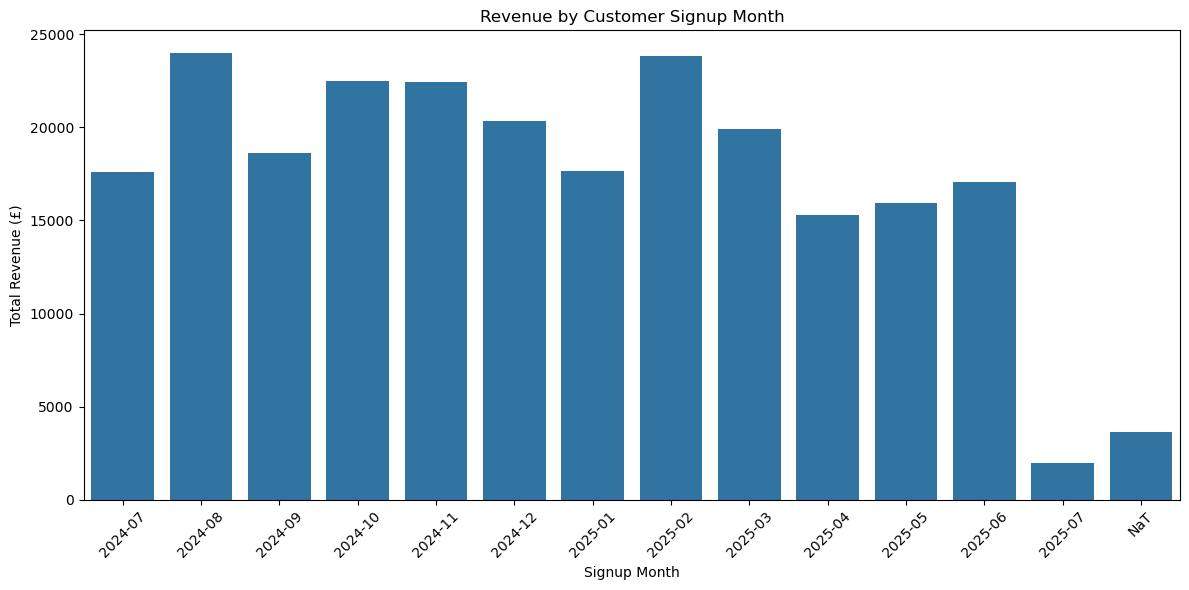

In [ ]:
# we can also visualise the relationships

plt.figure(figsize=(12,6))

sns.barplot(
    data=signup_activity,
    x='signup_month',
    y='revenue'
)

plt.title('Revenue by Customer Signup Month')
plt.xlabel('Signup Month')
plt.ylabel('Total Revenue (£)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 7. Do customer signup patterns influence purchasing activity?

The analysis indicates that customer signup timing has an impact on purchasing activity. Customers who signed up during certain months generated noticeably higher revenue and placed more orders than customers who joined during other periods.

The highest-performing signup cohort was August 2024, which generated approximately £24,009 in revenue from 277 orders. Customers who signed up in February 2025 also performed strongly, generating £23,829 from 277 orders. Other high-performing cohorts included October 2024 (£22,479) and November 2024 (£22,428).

In contrast, customers who signed up during later months such as April 2025 (£15,268) and May 2025 (£15,959) generated lower levels of revenue and fewer orders. This suggests that customers acquired during certain periods may be more engaged or have had more time to make repeat purchases.

Overall, the findings suggest that customer signup patterns do influence purchasing activity. Cohorts acquired during August 2024 and February 2025 delivered the strongest revenue performance, indicating that seasonal factors, marketing campaigns, or customer acquisition strategies during these periods may have been particularly effective. Green Cart Ltd. should investigate the acquisition channels and promotions used during these high-performing months and consider replicating them in future campaigns.


# 8. Op onal Stretch Tasks 

In [ ]:
# • Use .query() to extract:
# Customers who signed up in Q2  
q2_customers = customer_info.query(
    'signup_date.dt.month >= 4 and signup_date.dt.month <= 6',
    engine='python'
)

q2_customers.head()

,customer_id,email,signup_date,gender,region,loyalty_tier
0,C00001,shaneramirez@gmail.com,2025-04-26,Male,Central,Silver
2,C00003,howardmaurice@yahoo.com,2025-05-15,Male,Central,Gold
3,C00004,yherrera@arnold.org,2025-06-14,Female,Central,Gold
4,C00005,janetwilliams@gmail.com,2025-05-02,Male,West,Bronze
26,C00027,dwhite@baxter.info,2025-05-15,Male,North,Gold


In [ ]:
q2_customers.shape[0]

103

In [ ]:
# Q2 Customers from the Merged Dataset
q2_customers = merged_df.query(
    'signup_date.dt.quarter == 2',
    engine='python'
)

q2_customers.head()

,order_id,customer_id,product_id,quantity,unit_price,order_date,delivery_status,payment_method,region_x,discount_applied,...,region_y,loyalty_tier,revenue,order_week,price_band,days_to_order,email_domain,is_late,signup_month,discount_band
20,O216425,C00211,P0019,1.0,32.05,2025-07-28,Delayed,Bank Transfer,South,0.15,...,North,Silver,27.2425,31,High,376.0,anderson-bell.com,True,2025-05,10-20%
22,O930213,C00369,P0010,4.0,10.43,2025-07-26,Cancelled,Paypal,South,0.00,...,West,Bronze,41.7200,30,Low,346.0,yahoo.com,False,2025-06,0-10%
32,O960238,C00259,P0009,2.0,9.58,2025-07-16,Delayed,Credit Card,East,0.20,...,West,Gold,15.3280,29,Low,89.0,yahoo.com,True,2025-06,10-20%
33,O966135,C00464,P0028,1.0,26.29,2025-07-15,Cancelled,Paypal,West,0.00,...,Central,Gold,26.2900,29,Medium,96.0,hotmail.com,False,2025-04,0-10%
34,O453905,C00398,P0017,2.0,32.10,2025-07-14,Delivered,Paypal,South,0.10,...,Central,Bronze,57.7800,29,High,210.0,hotmail.com,False,2025-06,0-10%


In [ ]:
# verify
q2_customers[['customer_id', 'signup_date']].head()

,customer_id,signup_date
20,C00211,2025-05-17
22,C00369,2025-06-27
32,C00259,2025-06-25
33,C00464,2025-04-01
34,C00398,2025-06-15


In [ ]:
# Placed an order within 14 days
merged_df['days_to_order'] = (
    merged_df['order_date']
    - merged_df['launch_date']
).dt.days

In [ ]:
# Placed an order within 14 days
within_14_days = merged_df.query(
    'days_to_order <= 14'
)

within_14_days.head()

,order_id,customer_id,product_id,quantity,unit_price,order_date,delivery_status,payment_method,region_x,discount_applied,...,region_y,loyalty_tier,revenue,order_week,price_band,days_to_order,email_domain,is_late,signup_month,discount_band
58,O756742,C00077,P0013,5.0,13.70,2025-06-20,Delayed,Paypal,East,0.0,...,Central,Gold,68.50,25,Low,3.0,gould.com,True,2024-09,0-10%
110,O136068,C00421,P0012,1.0,21.09,2025-05-03,Cancelled,Credit Card,East,0.0,...,West,Gold,21.09,18,Medium,14.0,gonzalez.info,False,2025-05,0-10%
155,O544736,C00369,P0013,5.0,21.96,2025-06-17,Delivered,Credit Card,Central,0.2,...,West,Bronze,87.84,25,Medium,0.0,yahoo.com,False,2025-06,10-20%
165,O482836,C00469,P0013,2.0,41.10,2025-06-27,Delivered,Credit Card,North,0.1,...,North,Silver,73.98,26,High,10.0,washington.com,False,2025-01,0-10%
167,O515257,C00441,P0013,3.0,11.13,2025-06-29,Delayed,Credit Card,West,0.0,...,South,Bronze,33.39,26,Low,12.0,steele.com,True,NaT,0-10%


In [ ]:
within_14_days.shape[0]

60

In [ ]:
within_14_days[
    ['customer_id',
     'product_id',
     'launch_date',
     'order_date',
     'days_to_order']
].head()

,customer_id,product_id,launch_date,order_date,days_to_order
58,C00077,P0013,2025-06-17,2025-06-20,3.0
110,C00421,P0012,2025-04-19,2025-05-03,14.0
155,C00369,P0013,2025-06-17,2025-06-17,0.0
165,C00469,P0013,2025-06-17,2025-06-27,10.0
167,C00441,P0013,2025-06-17,2025-06-29,12.0


In [ ]:
# Received a discount > 20% 
high_discount_orders = merged_df.query(
    'discount_applied > 0.20'
)

high_discount_orders.head()

,order_id,customer_id,product_id,quantity,unit_price,order_date,delivery_status,payment_method,region_x,discount_applied,...,region_y,loyalty_tier,revenue,order_week,price_band,days_to_order,email_domain,is_late,signup_month,discount_band


In [ ]:
# count the records
high_discount_orders.shape[0]

0

In [ ]:
# view important columns
high_discount_orders[
    [
        'order_id',
        'customer_id',
        'product_id',
        'discount_applied',
        'revenue'
    ]
].head()

,order_id,customer_id,product_id,discount_applied,revenue


In [ ]:
# check for the highest discounts
high_discount_orders[
    ['discount_applied']
].describe()

,discount_applied
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN


# Use MinMaxScaler to normalise revenue or price  

In [ ]:
# normalize revenue
from sklearn.preprocessing import MinMaxScaler

# Create scaler
scaler = MinMaxScaler()

# Create new normalized column
merged_df['revenue_scaled'] = scaler.fit_transform(
    merged_df[['revenue']]
)

# Check results
merged_df[['revenue', 'revenue_scaled']].head()

,revenue,revenue_scaled
0,117.750,0.457431
1,94.600,0.361987
2,25.228,0.075976
3,26.208,0.080016
4,38.096,0.129029


In [ ]:
# verify the range
merged_df['revenue_scaled'].describe()

count    2999.000000
mean        0.302888
std         0.220819
min         0.000000
25%         0.123032
50%         0.249072
75%         0.453467
max         1.000000
Name: revenue_scaled, dtype: float64

In [ ]:
# Normalize unit price
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

merged_df['unit_price_scaled'] = scaler.fit_transform(
    merged_df[['unit_price']]
)

merged_df[['unit_price', 'unit_price_scaled']].head()

,unit_price,unit_price_scaled
0,39.25,0.744225
1,18.92,0.260062
2,29.68,0.516313
3,32.76,0.589664
4,47.62,0.943558


In [ ]:
# Flag underperforming products (low quan ty, high discount, delayed deliveries) 
# For the final stretch task, you need to identify products that meet all three conditions:

# 1. Low quantity sold
# 2. High discount applied
# 3. Delayed deliveries
# Step 1: Create Product-Level Summary
product_performance = (
    merged_df
    .groupby(['product_id', 'product_name'])
    .agg(
        avg_quantity=('quantity', 'mean'),
        avg_discount=('discount_applied', 'mean'),
        delay_count=('is_late', 'sum'),
        total_orders=('order_id', 'count')
    )
    .reset_index()
)

product_performance.head()

,product_id,product_name,avg_quantity,avg_discount,delay_count,total_orders
0,P0001,Storage Product 39,3.102273,0.082955,22,88
1,P0002,Cleaning Product 82,2.770115,0.080460,35,87
2,P0003,Cleaning Product 85,3.076923,0.095055,30,91
3,P0004,Kitchen Product 82,3.204082,0.068878,41,98
4,P0005,Personal Care Product 1,2.945652,0.094022,46,92


In [ ]:
# Step 2: Define Underperforming Criteria

 # A reasonable definition is:

# Average quantity < 3
# Average discount > 10%
# At least 1 delayed delivery
underperforming_products = product_performance.query(
    'avg_quantity < 3 and avg_discount > 0.10 and delay_count > 0'
)

underperforming_products

,product_id,product_name,avg_quantity,avg_discount,delay_count,total_orders


In [ ]:
# we can use use dynamic thresholds:
avg_qty = product_performance['avg_quantity'].mean()
avg_discount = product_performance['avg_discount'].mean()

underperforming_products = product_performance.query(
    'avg_quantity < @avg_qty and avg_discount > @avg_discount and delay_count > 0'
)

underperforming_products

,product_id,product_name,avg_quantity,avg_discount,delay_count,total_orders
4,P0005,Personal Care Product 1,2.945652,0.094022,46,92
7,P0008,Storage Product 47,2.545455,0.087879,33,99
11,P0012,Cleaning Product 29,2.731959,0.084021,34,97
26,P0027,Outdoors Product 55,2.750000,0.083621,38,116
29,P0030,Cleaning Product 72,2.938144,0.083505,34,97


In [ ]:
# Check How Many Products Were Flagged
underperforming_products.shape

(5, 6)

In [ ]:
# this means that 5 underperforming products were identified. The table contains 6 columns.